# SPT + Alternating: Degradación por tasa de pre-asignación vs Baseline

Análisis focalizado en la configuración **SPT + Alternating (excl=2)**, seleccionada como
escenario de referencia por su alineación estructural con el Hospital Base Puerto Montt.

Se evalúa cómo varían las métricas al aumentar la tasa de pre-asignación aleatoria
de **0 % a 100 % en pasos de 10 %** (11 tasas simuladas, 205 ventanas deslizantes cada una).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
from pathlib import Path
from scipy import stats

warnings.filterwarnings('ignore')

ROOT       = Path('../..')
DATA_DIR   = ROOT / 'data'
OUTPUT_DIR = ROOT / 'output' / 'analisis_preasignacion_spt_a'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SIM_CSV = DATA_DIR / 'resultados_spta_completo.csv'

PALETTE = {
    'baseline' : '#1565C0',
    'sim'      : '#53A76F',
    'neutral'  : '#546E7A',
}
COLOR_NP = '#1D9E75'
CUTOFF   = '2022-01-01'

RATES     = [round(i * 0.1, 1) for i in range(11)]   # 0.0, 0.1, ..., 1.0
RATES_PCT = [int(r * 100) for r in RATES]             # 0, 10, 20, ..., 100

def save(name: str):
    path = OUTPUT_DIR / f'{name}.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Guardado: {path}')

In [4]:
# ── Carga de datos ────────────────────────────────────────────
bl = pd.read_csv(DATA_DIR / 'resultados_baseline.csv', parse_dates=['weekStart'])
bl = bl.sort_values('weekStart').reset_index(drop=True)
bl_np = bl[bl['weekStart'] >= CUTOFF].copy()

sim = pd.read_csv(SIM_CSV)

# Resumen por tasa
grp = (
    sim.groupby('random_rate')
    [['throughput', 'lead_time', 'util_elec_pct', 'util_global_pct',
      'pre_assigned_count', 'pre_assigned_pct']]
    .agg(['mean', 'std', 'median'])
    .round(3)
)
grp.columns = ['_'.join(c) for c in grp.columns]
grp = grp.reset_index()

# Referencias del baseline
BL_MEAN_TP   = bl['totalSurgeries'].mean()
BL_MEAN_LT   = bl['avgLeadTimeDays'].mean()
BL_MEAN_UTIL = bl['utilGlobal_pct'].mean()
NP_MEAN_TP   = bl_np['totalSurgeries'].mean()
NP_MEAN_LT   = bl_np['avgLeadTimeDays'].mean()
NP_MEAN_UTIL = bl_np['utilGlobal_pct'].mean()

print(f'Baseline mean TP  : {BL_MEAN_TP:.2f}  |  Non-pandemic: {NP_MEAN_TP:.2f}')
print(f'Baseline mean LT  : {BL_MEAN_LT:.3f}  |  Non-pandemic: {NP_MEAN_LT:.3f}')
print(f'Baseline mean Util: {BL_MEAN_UTIL:.2f}% |  Non-pandemic: {NP_MEAN_UTIL:.2f}%')
print()
print('SPT + A por tasa (throughput medio):')
print(grp[['random_rate', 'throughput_mean', 'lead_time_mean',
           'util_elec_pct_mean', 'util_global_pct_mean']].to_string(index=False))

Baseline mean TP  : 136.19  |  Non-pandemic: 171.95
Baseline mean LT  : 2.636  |  Non-pandemic: 2.757
Baseline mean Util: 29.80% |  Non-pandemic: 38.07%

SPT + A por tasa (throughput medio):
 random_rate  throughput_mean  lead_time_mean  util_elec_pct_mean  util_global_pct_mean
         0.0          512.712           1.558              91.605                60.296
         0.1          480.410           1.670              86.508                57.238
         0.2          426.776           1.772              84.542                56.059
         0.3          373.624           1.935              85.896                56.870
         0.4          324.166           2.044              88.131                58.212
         0.5          295.517           2.111              90.074                59.377
         0.6          273.498           2.153              91.717                60.363
         0.7          255.683           2.175              92.722                60.967
         0.8     

## 1. Curva de degradación del throughput (0 % – 100 % pre-asignación)

Regresión lineal: TP = 479.23 + (-2.952) × rate
R² = 0.9191
Cruce con media no-pandemia (172.0): 104.1%
Cruce con media total       (136.2): 116.2%


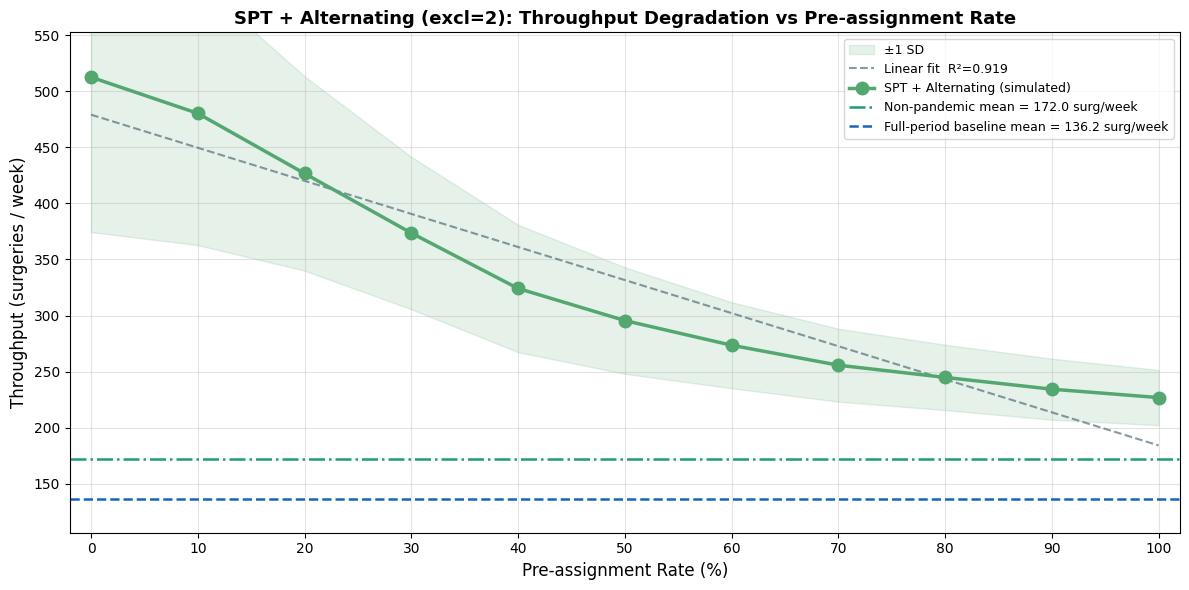

Guardado: ..\..\output\analisis_preasignacion_spt_a\pa_spta_degradacion_throughput.png


In [5]:
rates_obs = np.array(RATES_PCT)   # 0, 10, 20, ..., 100
tp_obs    = grp['throughput_mean'].values
tp_std    = grp['throughput_std'].values

# Regresión lineal sobre los 11 puntos observados
slope, intercept, r, p, se = stats.linregress(rates_obs, tp_obs)

# Tasa donde la recta cruza las referencias del baseline (dentro del rango observado)
rate_at_np_mean = (NP_MEAN_TP - intercept) / slope
rate_at_bl_mean = (BL_MEAN_TP - intercept) / slope

print(f'Regresión lineal: TP = {intercept:.2f} + ({slope:.3f}) × rate')
print(f'R² = {r**2:.4f}')
print(f'Cruce con media no-pandemia ({NP_MEAN_TP:.1f}): {rate_at_np_mean:.1f}%')
print(f'Cruce con media total       ({BL_MEAN_TP:.1f}): {rate_at_bl_mean:.1f}%')

# Línea de ajuste sobre el rango completo observado
rates_fit = np.linspace(0, 100, 400)
tp_fit    = intercept + slope * rates_fit

# ── Figura ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

# Banda ±1 SD
ax.fill_between(rates_obs, tp_obs - tp_std, tp_obs + tp_std,
                alpha=0.15, color=PALETTE['sim'], label='±1 SD')

# Ajuste lineal
ax.plot(rates_fit, tp_fit, '--', color=PALETTE['neutral'], linewidth=1.5,
        alpha=0.7, label=f'Linear fit  R²={r**2:.3f}')

# Puntos simulados
ax.plot(rates_obs, tp_obs, 'o-',
        color=PALETTE['sim'], linewidth=2.5, markersize=9,
        label='SPT + Alternating (simulated)')

# Referencias baseline
ax.axhline(NP_MEAN_TP, color=COLOR_NP, linestyle='-.', linewidth=1.8,
           label=f'Non-pandemic mean = {NP_MEAN_TP:.1f} surg/week')
ax.axhline(BL_MEAN_TP, color=PALETTE['baseline'], linestyle='--', linewidth=1.8,
           label=f'Full-period baseline mean = {BL_MEAN_TP:.1f} surg/week')

# Marcadores de cruce (dentro del rango observado)
for rate_cross, mean_val, color, label_txt in [
    (rate_at_np_mean, NP_MEAN_TP,   COLOR_NP,            f'~{rate_at_np_mean:.0f}%'),
    (rate_at_bl_mean, BL_MEAN_TP,   PALETTE['baseline'], f'~{rate_at_bl_mean:.0f}%'),
]:
    ax.plot(rate_cross, mean_val, 'v', color=color, markersize=11, zorder=5)
    ax.annotate(
        label_txt,
        xy=(rate_cross, mean_val),
        xytext=(rate_cross + 3, mean_val + 18),
        fontsize=10, fontweight='bold', color=color,
        arrowprops=dict(arrowstyle='->', color=color, lw=1.5)
    )

ax.set_xlabel('Pre-assignment Rate (%)', fontsize=12)
ax.set_ylabel('Throughput (surgeries / week)', fontsize=12)
ax.set_title(
    'SPT + Alternating (excl=2): Throughput Degradation vs Pre-assignment Rate',
    fontsize=13, fontweight='bold'
)
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.35)
ax.set_xlim(-2, 102)
ax.set_xticks(RATES_PCT)
ax.set_ylim(BL_MEAN_TP - 30, tp_obs[0] + 40)

plt.tight_layout()
save('pa_spta_degradacion_throughput')

## 2. Evolución de las tres métricas con la tasa de pre-asignación

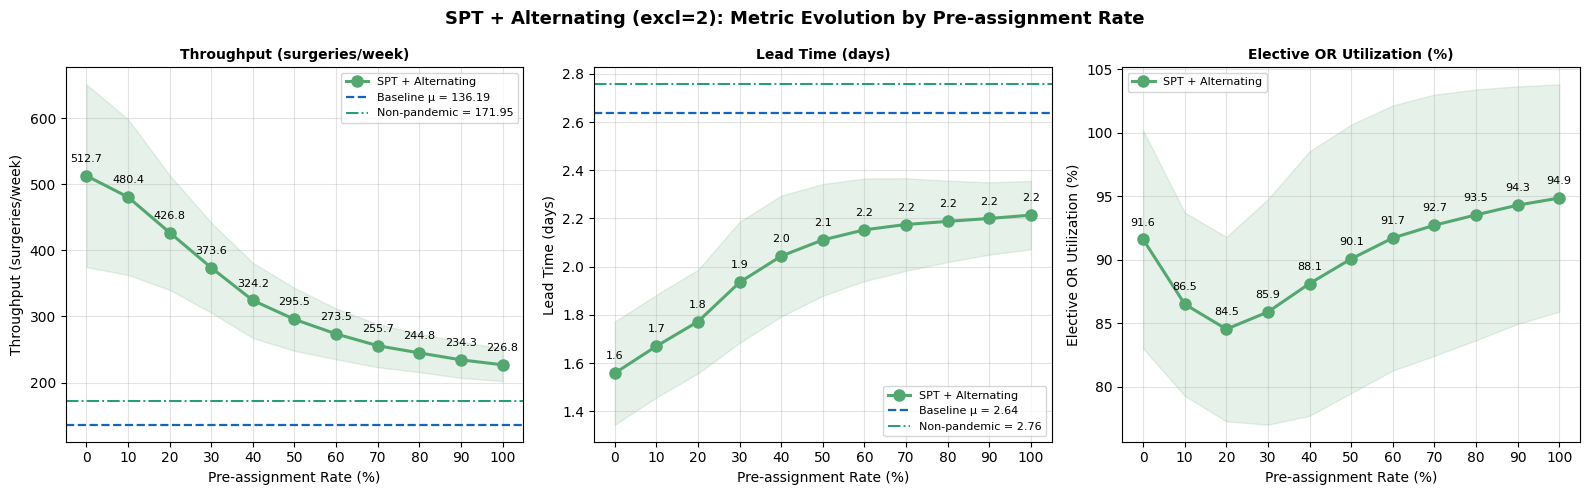

Guardado: ..\..\output\analisis_preasignacion_spt_a\pa_spta_metricas_por_tasa.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metric_cfg = [
    ('throughput_mean',    'throughput_std',    'Throughput (surgeries/week)',
     BL_MEAN_TP,   NP_MEAN_TP,   'lower is worse'),
    ('lead_time_mean',     'lead_time_std',     'Lead Time (days)',
     BL_MEAN_LT,   NP_MEAN_LT,   'higher is worse'),
    ('util_elec_pct_mean', 'util_elec_pct_std', 'Elective OR Utilization (%)',
     None,          None,          'lower is worse'),
]

for ax, (col_mean, col_std, ylabel, bl_ref, np_ref, direction) in zip(axes, metric_cfg):
    means = grp[col_mean].values
    stds  = grp[col_std].values

    ax.fill_between(RATES_PCT, means - stds, means + stds,
                    alpha=0.15, color=PALETTE['sim'])
    ax.plot(RATES_PCT, means, 'o-',
            color=PALETTE['sim'], linewidth=2.2, markersize=8,
            label='SPT + Alternating')

    for rate, val in zip(RATES_PCT, means):
        ax.annotate(f'{val:.1f}', xy=(rate, val),
                    xytext=(0, 10), textcoords='offset points',
                    ha='center', fontsize=8)

    if bl_ref is not None:
        ax.axhline(bl_ref, color=PALETTE['baseline'], linestyle='--',
                   linewidth=1.6, label=f'Baseline μ = {bl_ref:.2f}')
    if np_ref is not None:
        ax.axhline(np_ref, color=COLOR_NP, linestyle='-.',
                   linewidth=1.4, label=f'Non-pandemic = {np_ref:.2f}')

    ax.set_xlabel('Pre-assignment Rate (%)', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(ylabel, fontweight='bold', fontsize=10)
    ax.set_xticks(RATES_PCT)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.35)

fig.suptitle(
    'SPT + Alternating (excl=2): Metric Evolution by Pre-assignment Rate',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
save('pa_spta_metricas_por_tasa')

## 3. Distribución del throughput por tasa (boxplots)

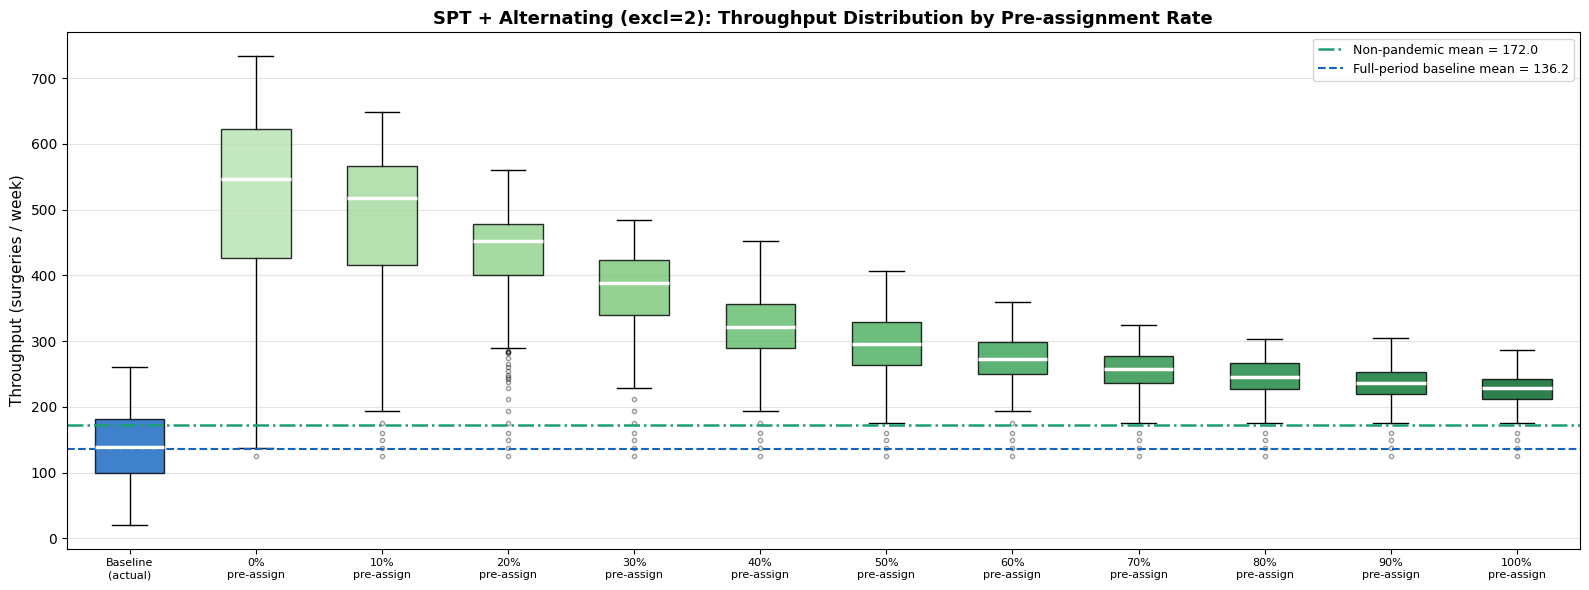

Guardado: ..\..\output\analisis_preasignacion_spt_a\pa_spta_boxplots_por_tasa.png


In [7]:
fig, ax = plt.subplots(figsize=(16, 6))

bl_data     = bl['totalSurgeries'].values
data_list   = [bl_data]
labels_list = ['Baseline\n(actual)']
colors_list = [PALETTE['baseline']]

greens = plt.cm.Greens(np.linspace(0.3, 0.9, len(RATES)))

for rate, color in zip(RATES, greens):
    subset = sim[np.isclose(sim['random_rate'], rate)]['throughput'].values
    data_list.append(subset)
    labels_list.append(f'{int(rate*100)}%\npre-assign')
    colors_list.append(color)

bp = ax.boxplot(data_list, patch_artist=True, widths=0.55,
                medianprops=dict(color='white', linewidth=2.5),
                flierprops=dict(marker='o', markersize=3, alpha=0.4))

for patch, color in zip(bp['boxes'], colors_list):
    patch.set_facecolor(color)
    patch.set_alpha(0.82)

ax.set_xticklabels(labels_list, fontsize=8)
ax.axhline(NP_MEAN_TP, color=COLOR_NP, linestyle='-.', linewidth=1.8,
           label=f'Non-pandemic mean = {NP_MEAN_TP:.1f}')
ax.axhline(BL_MEAN_TP, color=PALETTE['baseline'], linestyle='--', linewidth=1.5,
           label=f'Full-period baseline mean = {BL_MEAN_TP:.1f}')

ax.set_ylabel('Throughput (surgeries / week)', fontsize=11)
ax.set_title(
    'SPT + Alternating (excl=2): Throughput Distribution by Pre-assignment Rate',
    fontsize=13, fontweight='bold'
)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.35)
plt.tight_layout()
save('pa_spta_boxplots_por_tasa')

## 4. Costo marginal de la pre-asignación (pérdida respecto a tasa 0 %)

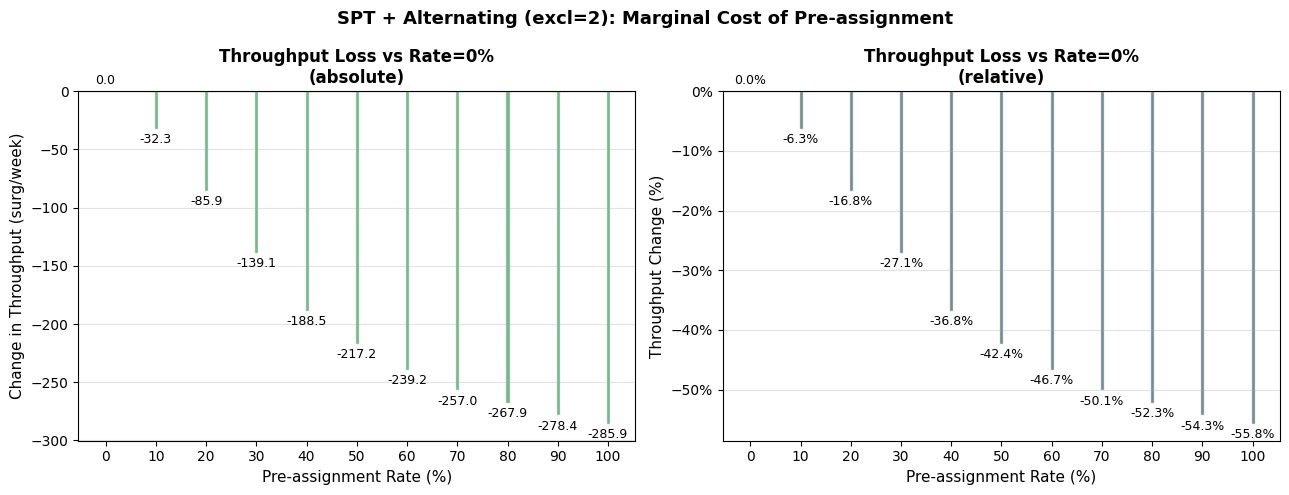

Guardado: ..\..\output\analisis_preasignacion_spt_a\pa_spta_costo_marginal.png


In [8]:
tp_base = grp.loc[grp['random_rate'] == 0.0, 'throughput_mean'].values[0]
lt_base = grp.loc[grp['random_rate'] == 0.0, 'lead_time_mean'].values[0]

loss_tp_abs  = grp['throughput_mean']   - tp_base   # negativo → pérdida
loss_tp_pct  = loss_tp_abs / tp_base * 100
gain_lt_abs  = grp['lead_time_mean']    - lt_base   # positivo → empeora
gain_lt_pct  = gain_lt_abs / lt_base * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pérdida absoluta de throughput
ax = axes[0]
bars = ax.bar(RATES_PCT, loss_tp_abs, color=PALETTE['sim'], alpha=0.8, edgecolor='white')
ax.bar_label(bars, fmt='%.1f', fontsize=9, padding=3)
ax.set_xlabel('Pre-assignment Rate (%)', fontsize=11)
ax.set_ylabel('Change in Throughput (surg/week)', fontsize=11)
ax.set_title('Throughput Loss vs Rate=0%\n(absolute)', fontweight='bold')
ax.set_xticks(RATES_PCT)
ax.grid(axis='y', alpha=0.35)
ax.axhline(0, color='black', linewidth=0.8)

# Pérdida porcentual
ax2 = axes[1]
bars2 = ax2.bar(RATES_PCT, loss_tp_pct, color=PALETTE['neutral'], alpha=0.8, edgecolor='white')
ax2.bar_label(bars2, fmt='%.1f%%', fontsize=9, padding=3)
ax2.set_xlabel('Pre-assignment Rate (%)', fontsize=11)
ax2.set_ylabel('Throughput Change (%)', fontsize=11)
ax2.set_title('Throughput Loss vs Rate=0%\n(relative)', fontweight='bold')
ax2.set_xticks(RATES_PCT)
ax2.grid(axis='y', alpha=0.35)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter())

fig.suptitle(
    'SPT + Alternating (excl=2): Marginal Cost of Pre-assignment',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
save('pa_spta_costo_marginal')

## 5. Cirugías efectivamente pre-asignadas vs tasa solicitada

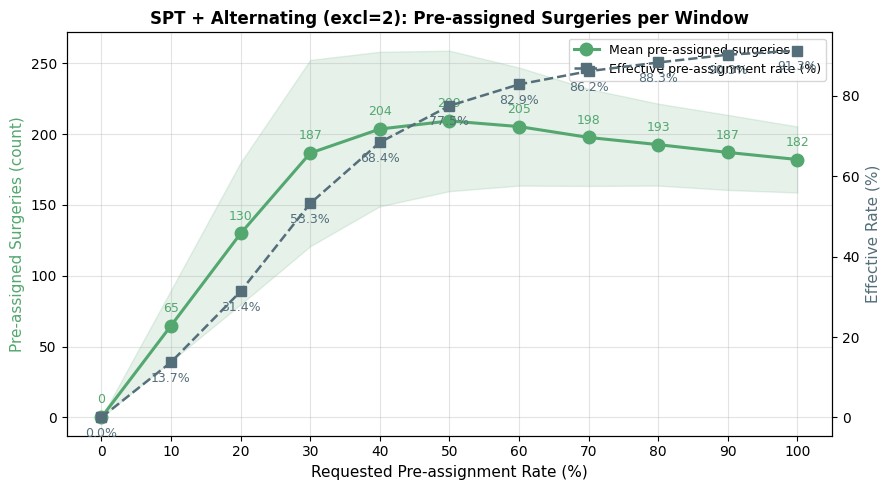

Guardado: ..\..\output\analisis_preasignacion_spt_a\pa_spta_cirugias_preasignadas.png


In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(RATES_PCT, grp['pre_assigned_count_mean'], 'o-',
        color=PALETTE['sim'], linewidth=2.2, markersize=9,
        label='Mean pre-assigned surgeries')
ax.fill_between(RATES_PCT,
                grp['pre_assigned_count_mean'] - grp['pre_assigned_count_std'],
                grp['pre_assigned_count_mean'] + grp['pre_assigned_count_std'],
                alpha=0.15, color=PALETTE['sim'])

ax2 = ax.twinx()
ax2.plot(RATES_PCT, grp['pre_assigned_pct_mean'], 's--',
         color=PALETTE['neutral'], linewidth=1.8, markersize=7,
         label='Effective pre-assignment rate (%)')

for rate, cnt, pct in zip(RATES_PCT,
                           grp['pre_assigned_count_mean'],
                           grp['pre_assigned_pct_mean']):
    ax.annotate(f'{cnt:.0f}', xy=(rate, cnt), xytext=(0, 10),
                textcoords='offset points', ha='center', fontsize=9,
                color=PALETTE['sim'])
    ax2.annotate(f'{pct:.1f}%', xy=(rate, pct), xytext=(0, -14),
                 textcoords='offset points', ha='center', fontsize=9,
                 color=PALETTE['neutral'])

ax.set_xlabel('Requested Pre-assignment Rate (%)', fontsize=11)
ax.set_ylabel('Pre-assigned Surgeries (count)', fontsize=11, color=PALETTE['sim'])
ax2.set_ylabel('Effective Rate (%)', fontsize=11, color=PALETTE['neutral'])
ax.set_xticks(RATES_PCT)
ax.set_title(
    'SPT + Alternating (excl=2): Pre-assigned Surgeries per Window',
    fontsize=12, fontweight='bold'
)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9)
ax.grid(alpha=0.35)
plt.tight_layout()
save('pa_spta_cirugias_preasignadas')

## 6. Tabla resumen

In [10]:
tp_vals  = grp['throughput_mean'].values
lt_vals  = grp['lead_time_mean'].values
ue_vals  = grp['util_elec_pct_mean'].values
pa_cnt   = grp['pre_assigned_count_mean'].values
pa_pct   = grp['pre_assigned_pct_mean'].values

summary = pd.DataFrame({
    'Rate (%)':              [f'{r}%' for r in RATES_PCT],
    'Throughput':            tp_vals.round(1),
    'TP vs BL (×)':         (tp_vals / BL_MEAN_TP).round(2),
    'TP vs NP (×)':         (tp_vals / NP_MEAN_TP).round(2),
    'TP loss vs 0% (%)':     ((tp_vals - tp_vals[0]) / tp_vals[0] * 100).round(1),
    'Lead Time (d)':         lt_vals.round(3),
    'LT vs BL (%)':          ((lt_vals - BL_MEAN_LT) / BL_MEAN_LT * 100).round(1),
    'Util Elec (%)':         ue_vals.round(1),
    'Pre-assigned (n)':      pa_cnt.round(0).astype(int),
    'Effective Rate (%)':    pa_pct.round(1),
})

print('=== SPT + Alternating (excl=2): Resumen por tasa ===')
print(summary.to_string(index=False))

=== SPT + Alternating (excl=2): Resumen por tasa ===
Rate (%)  Throughput  TP vs BL (×)  TP vs NP (×)  TP loss vs 0% (%)  Lead Time (d)  LT vs BL (%)  Util Elec (%)  Pre-assigned (n)  Effective Rate (%)
      0%       512.7          3.76          2.98                0.0          1.558         -40.9           91.6                 0                 0.0
     10%       480.4          3.53          2.79               -6.3          1.670         -36.6           86.5                65                13.7
     20%       426.8          3.13          2.48              -16.8          1.772         -32.8           84.5               130                31.4
     30%       373.6          2.74          2.17              -27.1          1.935         -26.6           85.9               187                53.3
     40%       324.2          2.38          1.89              -36.8          2.044         -22.5           88.1               204                68.4
     50%       295.5          2.17          1.7